# 02 — Two-stage anchor-based detector: Faster R-CNN

Rubric item: *Two-stage anchor-based*. Numbers are read from `results/` (written by `scripts/05_evaluate.py` and `07_failure_cases.py`); nothing here is retyped by hand.

In [1]:
import json, sys
from pathlib import Path
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "scripts"))
from common import CLASS_NAMES

def show(name, width=900, folder="images"):
    display(Image(filename=str(ROOT / folder / name), width=width))

def table(rows, header):
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)] + ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

def load(path):
    p = ROOT / path
    return json.loads(p.read_text()) if p.is_file() else None

f3 = lambda v: "n/a" if v is None else f"{v:.3f}"

## Starting point: the earlier Colab run


- **Model:** TorchVision Faster R-CNN, ResNet-50 FPN, COCO-pretrained, box predictor replaced for 8 classes + background.
- **Data:** every 5th frame of each of the 56 training clips (4,868 frames); validation on whole clips.
- **Training (Colab T4):** a one-epoch pilot on 271 frames (AdamW, lr 1e-4), then SGD (lr 0.005, momentum 0.9, weight decay 5e-4, batch 1). A quick check on 219 validation frames every 1,000 steps. The run was stopped by hand at step 3,755; this is the checkpoint scored below.
- **Not tuned yet:** the run used TorchVision defaults for the proposal stage and RoI sampling.

### Progress of this model

| stage | mAP | AP50 | AP small |
|---|---|---|---|
| pilot: 271 frames, 1 epoch | 0.081 | 0.179 | 0.049 |
| 4,868 frames, step 1,755 | 0.114 | 0.251 | 0.057 |
| 4,868 frames, step 3,755 | 0.124 | 0.265 | 0.056 |

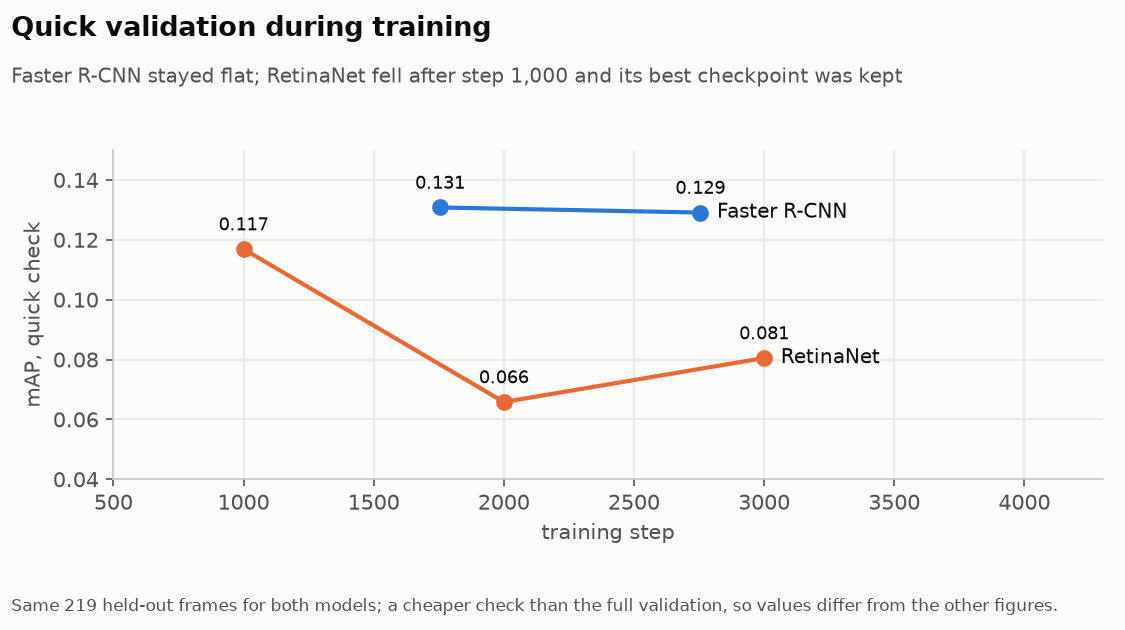

In [2]:
m = load("results/notebook/milestones.json")
table([[s["stage"], f3(s["mAP"]), f3(s["AP50"]), f3(s["AP_small"])] for s in m["full_validation_in_order"] if s["run"] == "Faster R-CNN"], ["stage", "mAP", "AP50", "AP small"])
show("fig_quick_validation.png", 700)

*The step-3,755 row is the value recorded in Colab. The results below score the same checkpoint again with the protocol used for every model here (score threshold 0.001, up to 500 detections per frame), which keeps more low-confidence boxes and gives a higher mAP. The weights did not change.*

## Results of the best run of this family on the validation split

All 2,846 frames of the 7 validation clips, COCO metrics with ignored regions respected, up to 500 detections per frame. Speed is the time of one forward pass per frame at batch size 1 on this Mac's GPU (MPS), the same for every model, so it is comparable across models but not with the earlier T4 timings.

In [3]:
r = load("results/eval/frcnn-base.json")
table([[f3(r["AP"]), f3(r["AP50"]), f3(r["AP75"]), f3(r["AP_small"]), f3(r["AP_medium"]), f3(r["AP_large"]), f'{r["ms_per_frame"]:.0f}']],
      ["mAP", "AP50", "AP75", "AP small", "AP medium", "AP large", "ms per frame"])
table([[c, f3(v)] for c, v in r["per_class"].items()], ["class", "AP"])

| mAP | AP50 | AP75 | AP small | AP medium | AP large | ms per frame |
|---|---|---|---|---|---|---|
| 0.170 | 0.362 | 0.136 | 0.066 | 0.155 | 0.327 | 131 |

| class | AP |
|---|---|
| person | 0.218 |
| bicycle | 0.167 |
| car | 0.339 |
| van | 0.171 |
| truck | 0.159 |
| tricycle | 0.186 |
| bus | 0.020 |
| motor | 0.098 |

### By clip

In [4]:
r = load("results/eval/frcnn-base.json")
table([[c, v["frames"], f3(v["AP"]), f3(v["AP50"]), f3(v["AP_small"])] for c, v in sorted(r["per_clip"].items(), key=lambda kv: -(kv[1]["AP"] or 0))],
      ["validation clip", "frames", "AP", "AP50", "AP small"])

| validation clip | frames | AP | AP50 | AP small |
|---|---|---|---|---|
| uav0000137_00458_v | 233 | 0.238 | 0.539 | 0.008 |
| uav0000117_02622_v | 349 | 0.224 | 0.461 | 0.015 |
| uav0000339_00001_v | 275 | 0.215 | 0.436 | 0.066 |
| uav0000305_00000_v | 184 | 0.184 | 0.288 | 0.033 |
| uav0000182_00000_v | 363 | 0.129 | 0.308 | 0.079 |
| uav0000086_00000_v | 464 | 0.115 | 0.332 | 0.168 |
| uav0000268_05773_v | 978 | 0.101 | 0.165 | 0.015 |

## Failure cases

Detections with score >= 0.3 matched to ground truth at IoU 0.5 (detections inside ignored regions dropped). A box found with the wrong class counts as a miss. Green = found, red = missed, blue = false positive.

In [5]:
f = load("results/failures/frcnn-base.json")
table([[k, f"{v:.0%}"] for k, v in f["recall_by_size"].items()], ["object size", "share found"])
table([[k, f"{v:.0%}"] for k, v in f["recall_by_class"].items()], ["class", "share found"])
table([[p["truth"], p["predicted"], p["count"]] for p in f["top_class_confusions"]], ["true class", "predicted as", "count"])
table([[c, v["frames"], f'{v["recall"]:.0%}', v["false_positives_per_frame"]] for c, v in sorted(f["clips"].items(), key=lambda kv: kv[1]["recall"])], ["clip", "frames", "share found", "false positives per frame"])

| object size | share found |
|---|---|
| small | 36% |
| medium | 52% |
| large | 67% |

| class | share found |
|---|---|
| person | 61% |
| motor | 37% |
| bicycle | 20% |
| car | 61% |
| tricycle | 19% |
| van | 3% |
| truck | 37% |
| bus | 4% |

| true class | predicted as | count |
|---|---|---|
| van | car | 4104 |
| bicycle | motor | 1575 |
| motor | person | 1508 |
| person | motor | 673 |
| tricycle | motor | 544 |
| tricycle | car | 484 |
| bicycle | person | 332 |
| tricycle | truck | 299 |

| clip | frames | share found | false positives per frame |
|---|---|---|---|
| uav0000268_05773_v | 978 | 12% | 1.4 |
| uav0000182_00000_v | 363 | 39% | 20.2 |
| uav0000339_00001_v | 275 | 48% | 8.0 |
| uav0000117_02622_v | 349 | 51% | 12.9 |
| uav0000137_00458_v | 233 | 57% | 20.1 |
| uav0000305_00000_v | 184 | 66% | 18.2 |
| uav0000086_00000_v | 464 | 71% | 17.3 |

01_uav0000137_00458_v_0167_missed64_fp33.jpg


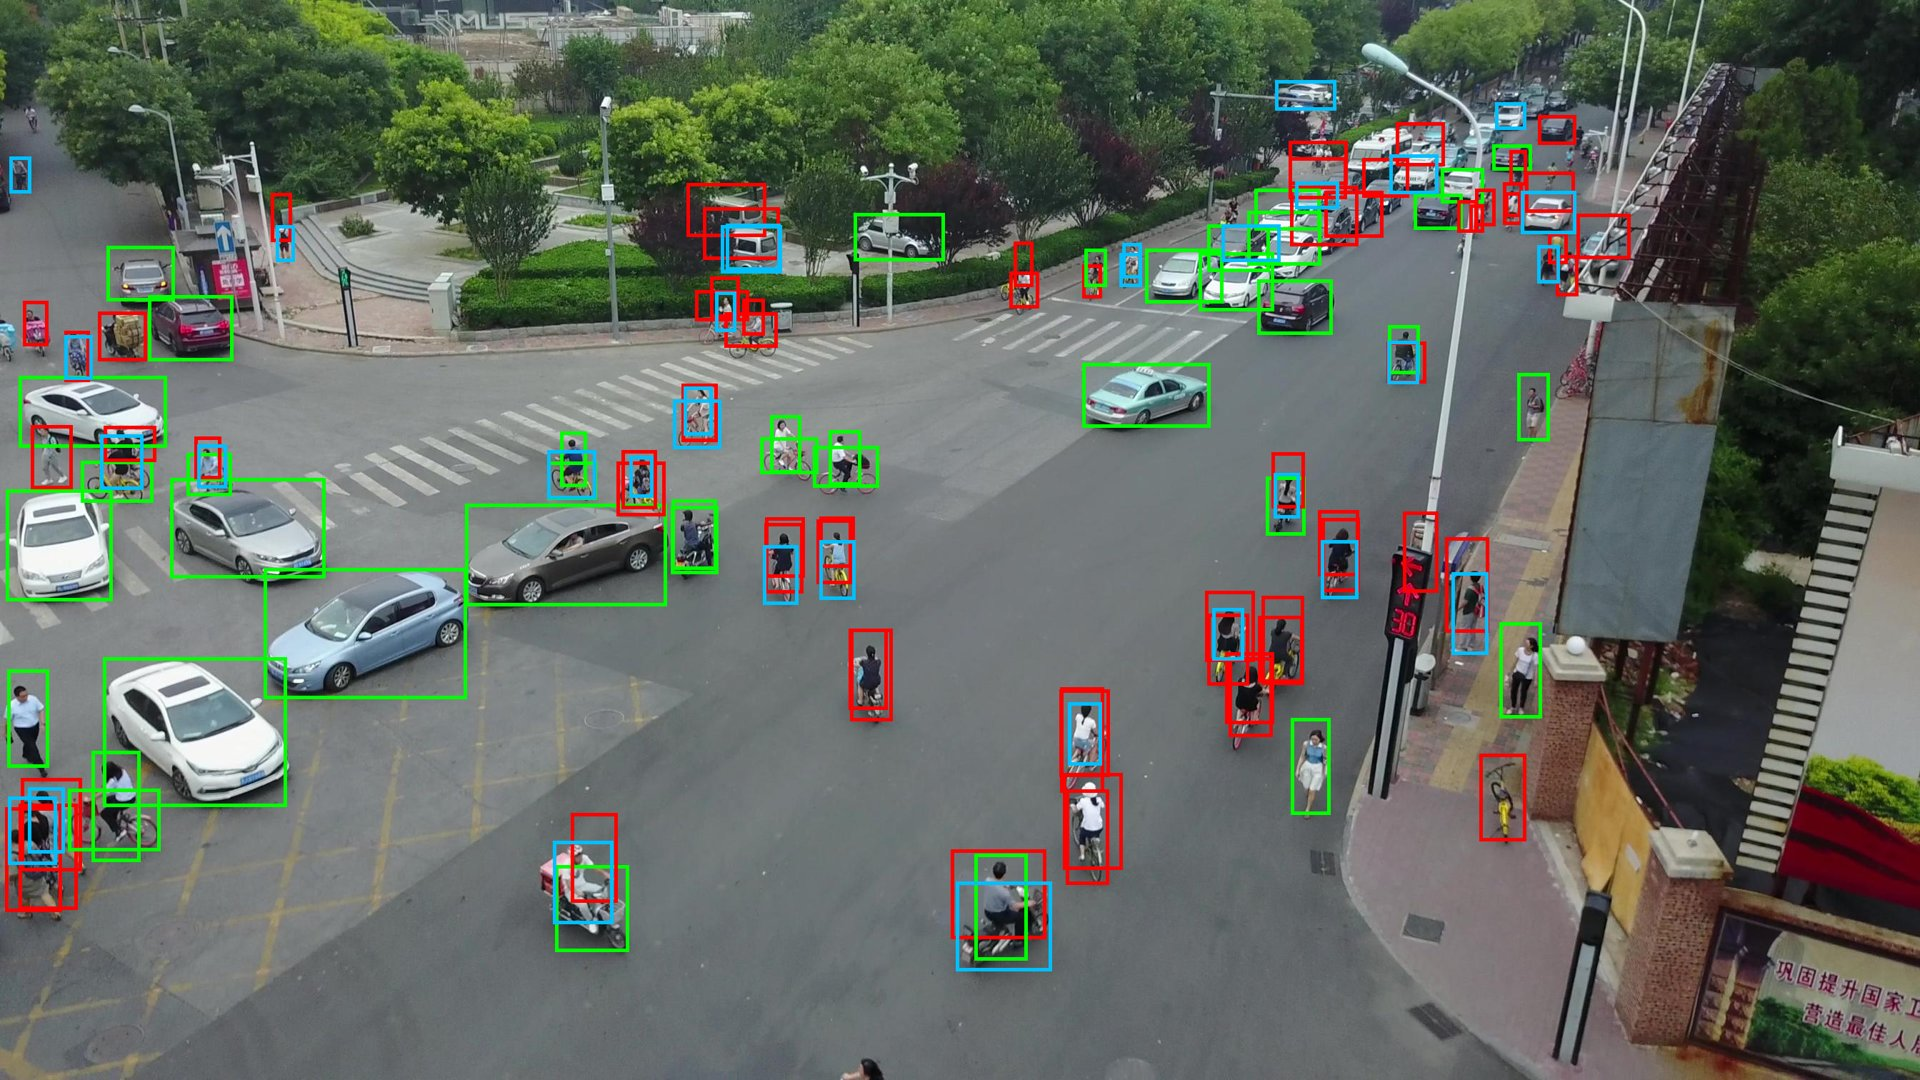

02_uav0000137_00458_v_0111_missed60_fp35.jpg


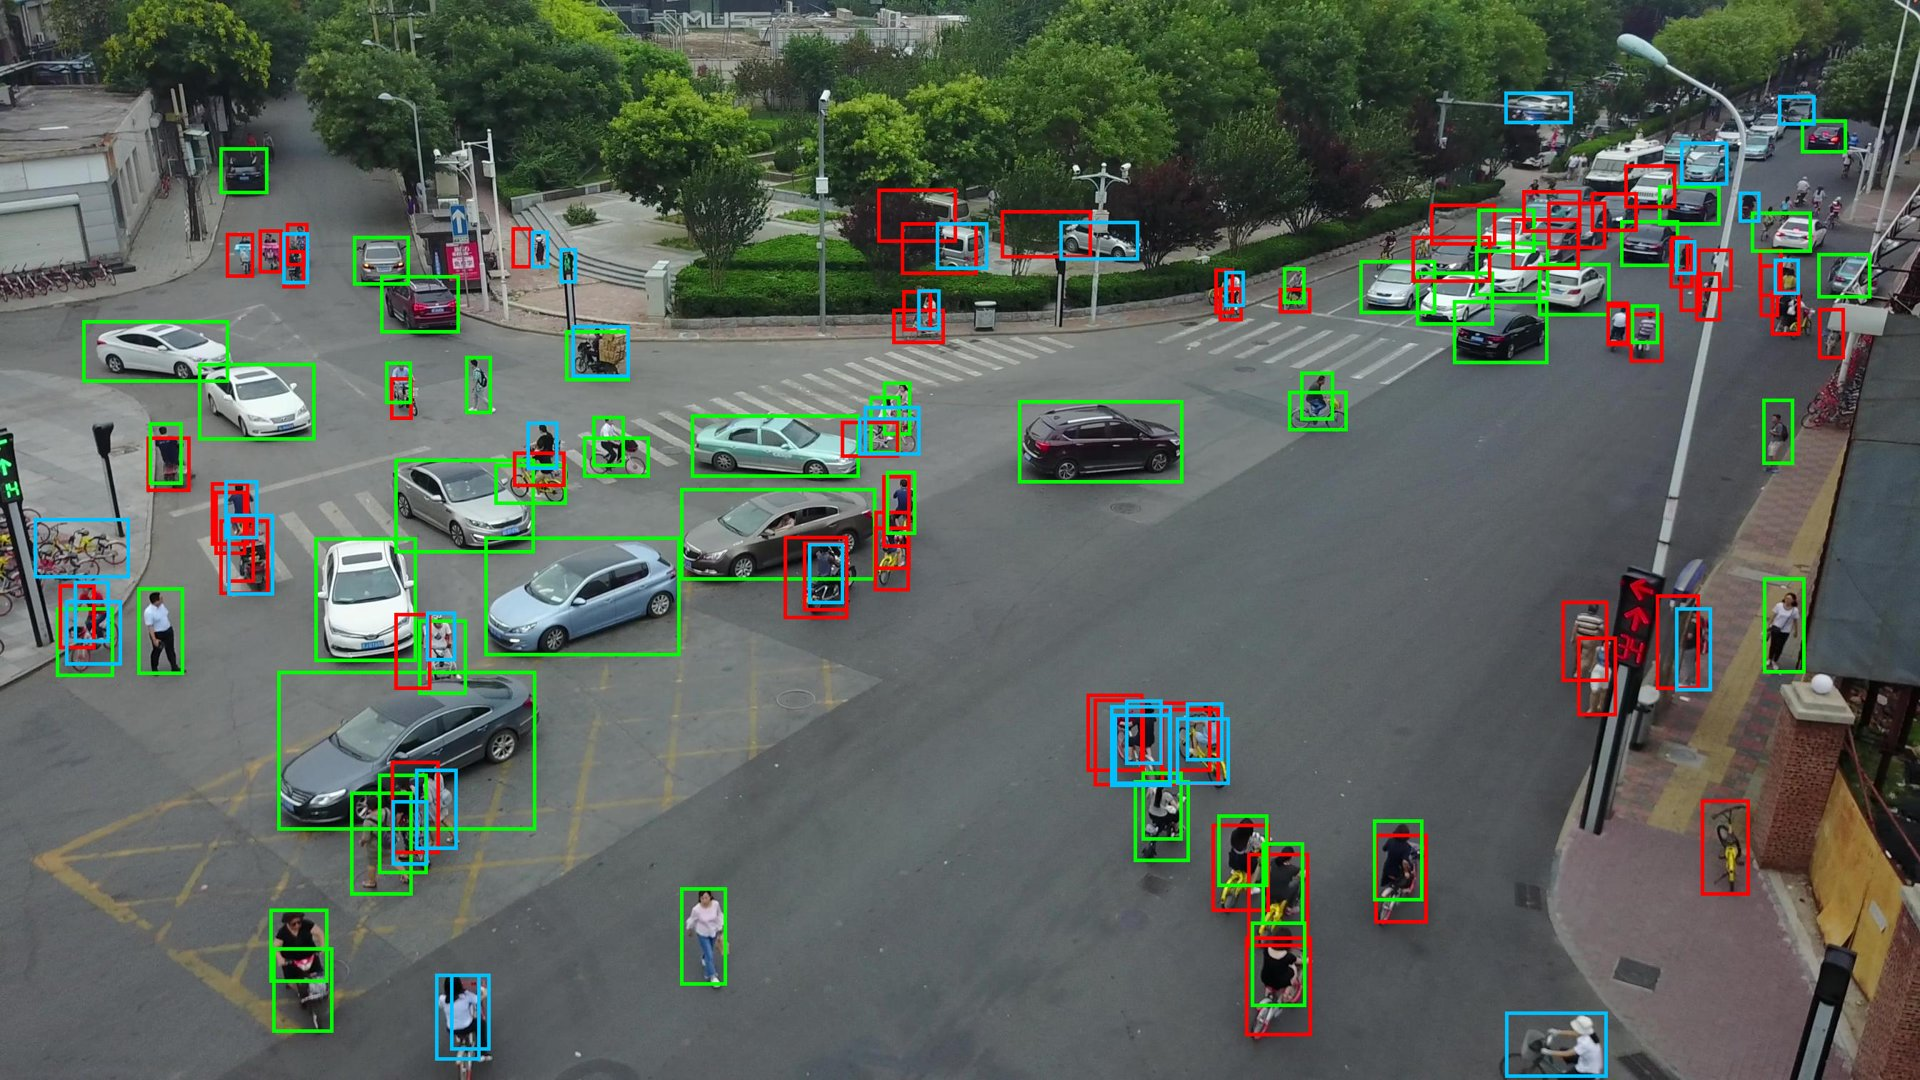

03_uav0000137_00458_v_0142_missed69_fp26.jpg


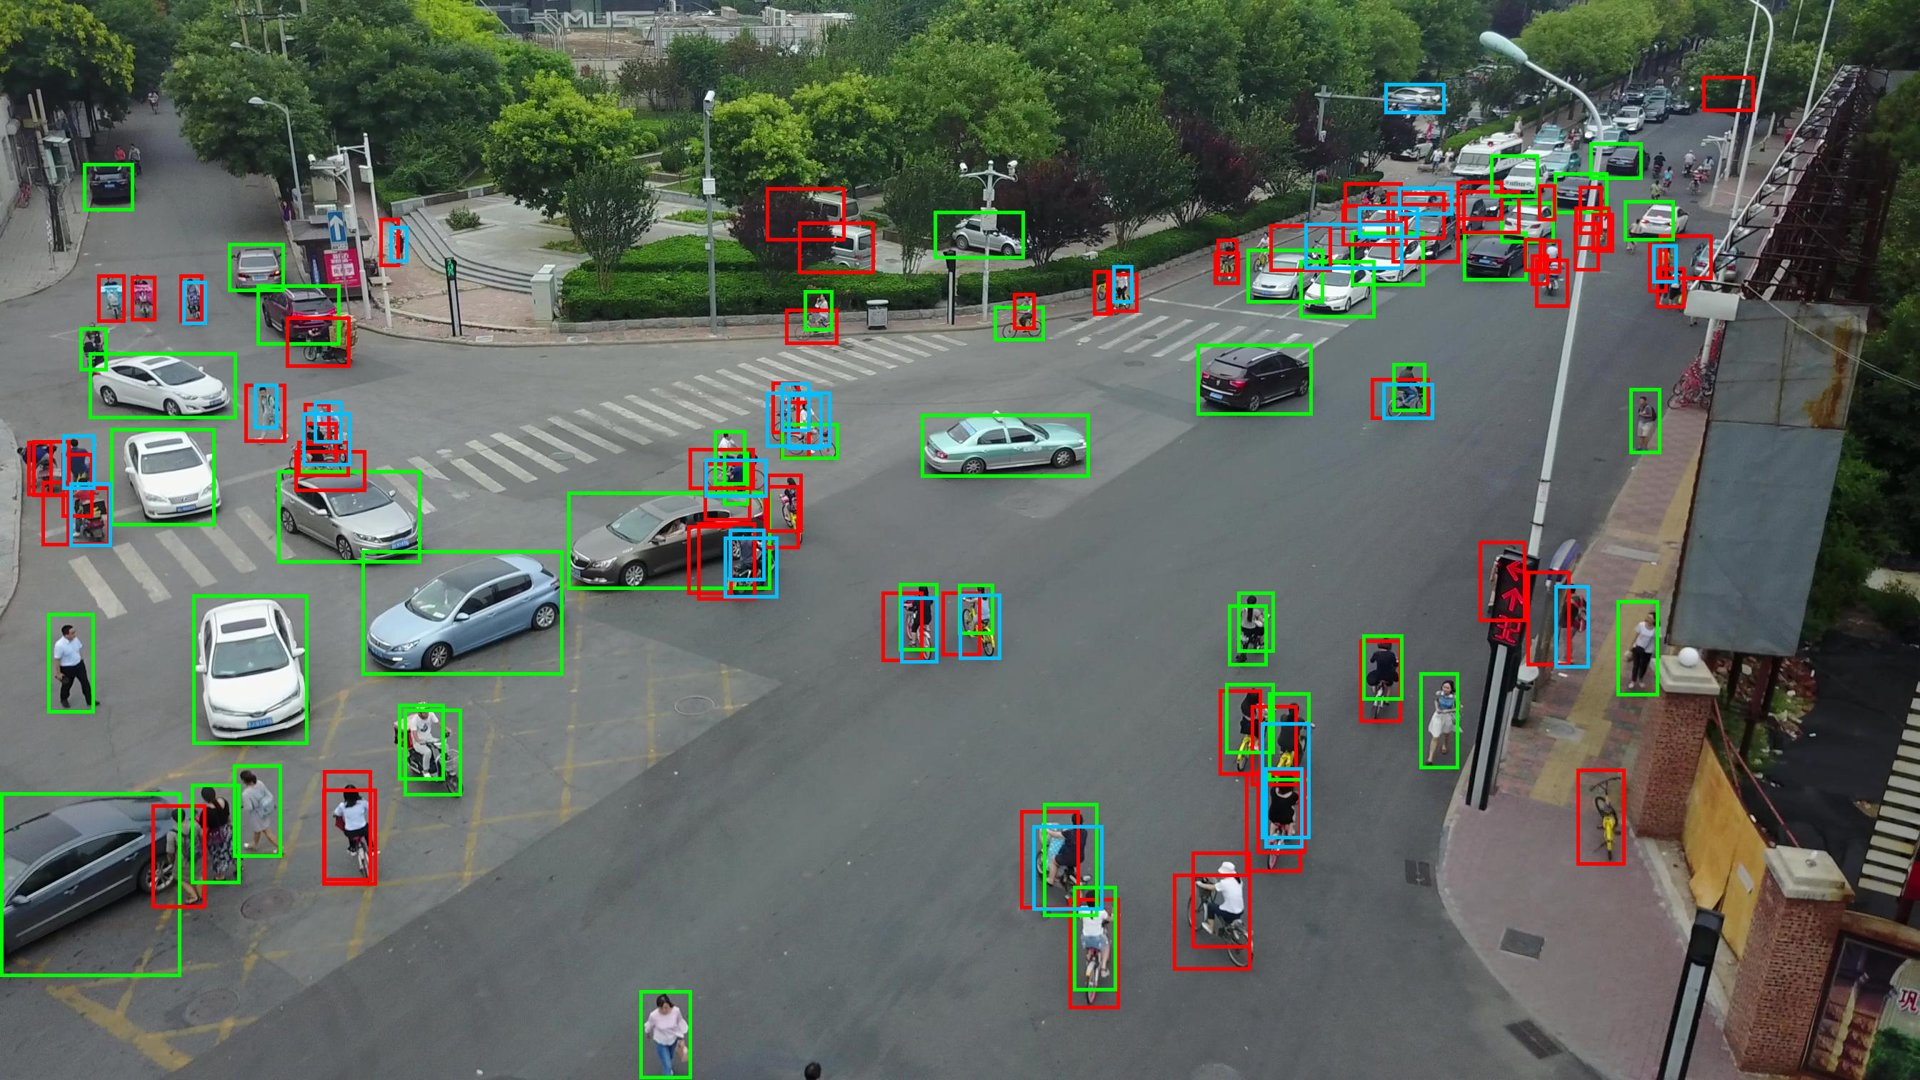

In [6]:
for path in sorted((ROOT / "runs" / "failures" / "frcnn-base").glob("*.jpg"))[:3]:
    print(path.name)
    display(Image(filename=str(path), width=900))

## Tuning experiments

Every run starts from the same COCO weights, trains on the same 4,868 frames for the same short budget on one machine (a Mac Mini, Apple GPU), and changes one thing against the baseline run of its family (`EXPERIMENTS.md` has the protocol and the commands):

- `frcnn-base`: TorchVision defaults, 15 minutes
- `frcnn-rpn300`: region proposals kept per image 2000 → 300
- `frcnn-roi128`: RoI samples per image 512 → 128

The table lists every run of this family scored with `scripts/05_evaluate.py` on all validation frames.

In [7]:
rows = []
for path in sorted((ROOT / "results" / "eval").glob("frcnn-*.json")):
    r = json.loads(path.read_text())
    rows.append([r["name"], f3(r["AP"]), f3(r["AP50"]), f3(r["AP_small"]), f'{r["ms_per_frame"]:.0f}'])
table(rows, ["run", "AP", "AP50", "AP small", "ms per frame"]) if rows else print("no tuned runs evaluated yet")

| run | AP | AP50 | AP small | ms per frame |
|---|---|---|---|---|
| frcnn-base | 0.170 | 0.362 | 0.066 | 131 |
| frcnn-roi128 | 0.151 | 0.328 | 0.063 | 110 |
| frcnn-rpn300 | 0.137 | 0.289 | 0.061 | 109 |